# Manufacturing Quality Analytics
A guided exploration of a fully synthetic quality dataset.


## 1. Load libraries and data


In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
data_path = ROOT / 'data' / 'raw' / 'synthetic_quality_data.csv'
df = pd.read_csv(data_path, parse_dates=['inspection_date'])
df.head()


,inspection_date,product_family,supplier,production_line,shift,units_inspected,defect_units,defect_category,severity,downtime_minutes
0,2025-01-02,Hydraulic Valve,Supplier D,Line 1,Afternoon,430,21,Dimensional,Low,37
1,2025-01-03,Hydraulic Valve,Supplier B,Line 1,Night,264,13,Dimensional,Low,37
2,2025-01-03,Control Unit,Supplier D,Line 1,Morning,481,9,Assembly,Medium,54
3,2025-01-03,Sensor Module,Supplier A,Line 1,Afternoon,231,6,Surface Finish,High,21
4,2025-01-04,Sensor Module,Supplier A,Line 1,Night,333,7,Leakage,Medium,19


## 2. Check data quality


In [2]:
print('Shape:', df.shape)
display(df.isna().sum().to_frame('missing_values'))
assert (df['units_inspected'] > 0).all()
assert (df['defect_units'] <= df['units_inspected']).all()


Shape: (600, 10)


,missing_values
inspection_date,0
product_family,0
supplier,0
production_line,0
shift,0
units_inspected,0
defect_units,0
defect_category,0
severity,0
downtime_minutes,0


## 3. Calculate headline KPIs


In [3]:
total_inspected = df['units_inspected'].sum()
total_defects = df['defect_units'].sum()
overall_defect_rate = total_defects / total_inspected
print(f'Inspection records: {len(df):,}')
print(f'Units inspected: {total_inspected:,}')
print(f'Defective units: {total_defects:,}')
print(f'Overall defect rate: {overall_defect_rate:.2%}')


Inspection records: 600
Units inspected: 173,562
Defective units: 6,101
Overall defect rate: 3.52%


## 4. Monthly defect-rate trend


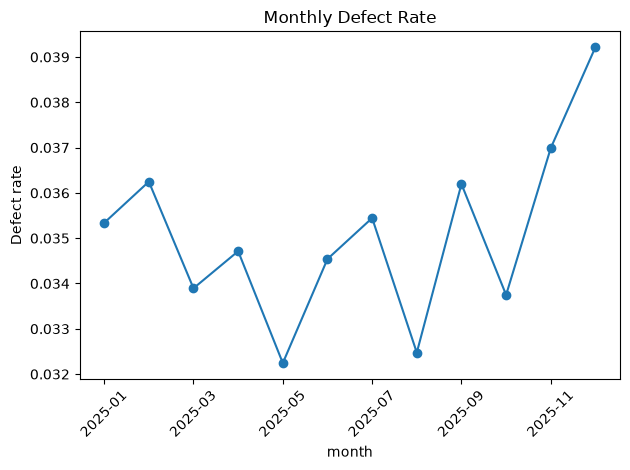

In [4]:
df['month'] = df['inspection_date'].dt.to_period('M').astype(str)
monthly = df.groupby('month', as_index=False).agg(
    units_inspected=('units_inspected', 'sum'),
    defect_units=('defect_units', 'sum')
)
monthly['defect_rate'] = monthly['defect_units'] / monthly['units_inspected']
ax = monthly.plot(x='month', y='defect_rate', marker='o', legend=False,
                  title='Monthly Defect Rate')
ax.set_ylabel('Defect rate')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()


## 5. Compare suppliers
Compare rates alongside inspected volume; a rate based on a small volume may be less stable.


In [5]:
supplier_summary = df.groupby('supplier', as_index=False).agg(
    units_inspected=('units_inspected', 'sum'),
    defect_units=('defect_units', 'sum')
)
supplier_summary['defect_rate'] = (
    supplier_summary['defect_units'] / supplier_summary['units_inspected']
)
supplier_summary.sort_values('defect_rate', ascending=False)


,supplier,units_inspected,defect_units,defect_rate
1,Supplier B,37216,1504,0.040413
3,Supplier D,32272,1239,0.038392
0,Supplier A,36639,1267,0.034581
4,Supplier E,35732,1122,0.031400
2,Supplier C,31703,969,0.030565


## 6. Defect categories and interpretation


In [6]:
category_summary = (df.groupby('defect_category', as_index=False)
                    .agg(defect_units=('defect_units', 'sum'))
                    .sort_values('defect_units', ascending=False))
category_summary


,defect_category,defect_units
0,Assembly,1436
4,Surface Finish,1281
3,Leakage,1173
2,Electrical,1124
1,Dimensional,1087


## 7. Conclusions

### Observations

1. **Defect rate:** The overall defect rate is **3.52%**. Monthly analysis shows that **December has the highest defect rate (3.92%)**, while **May has the lowest (3.22%)**.

2. **Supplier performance:** Supplier-level summaries show differences in recorded defect rates. In this synthetic dataset, **Supplier B has the highest defect rate (4.04%)**, while **Supplier C has the lowest (3.06%)**.

3. **Defect categories:** The defect-category summary identifies which categories account for the largest number of defective units. The most frequent category is **Assembly, with 1,436 defective units**.

### Limitation

The dataset is synthetic and contains generated records. Therefore, the patterns do not represent actual manufacturing performance and cannot be used to evaluate real suppliers or production lines.

### Recommendation

For a real manufacturing quality analysis, use validated production and inspection data, monitor defect rates over time, and investigate suppliers or defect categories that show consistently higher rates. Supplier comparisons should also consider inspection volumes and product mix.
